# Лаб. 3. Оптимізація функції Easom генетичним алгоритмом

**Тестова функція — Easom** (з таблиці тестових функцій для оптимізації):
$$f(x,y) = -\cos(x)\cos(y)\exp\!\Big(-\big((x-\pi)^2 + (y-\pi)^2\big)\Big),\qquad -100 \le x,y \le 100$$

**Глобальний мінімум:** $f(\pi,\pi) = -1$.

Задача: реалізувати генетичний алгоритм (ГА), який знаходить екстремум (мінімум) цієї функції, і показати візуально, як він працює.

## 1. Функція та перевірка

Реалізуємо $f$ векторизовано (через `numpy`), щоб одразу рахувати значення для всієї популяції або для сітки точок. Перевіримо, що $f(\pi,\pi) = -1$.

In [1]:
import numpy as np; import matplotlib.pyplot as plt

def easom(x, y):
    return -np.cos(x) * np.cos(y) * np.exp(-((x - np.pi)**2 + (y - np.pi)**2))

LO, HI = -100, 100
X_OPT = np.array([np.pi, np.pi])
F_OPT = -1

print('f(pi, pi) =', easom(np.pi, np.pi))

f(pi, pi) = -1.0


## 2. Огляд функції

Через множник $\exp\!\big(-[(x-\pi)^2 + (y-\pi)^2]\big)$ функція майже на всій області дорівнює $\approx 0$, а весь рельєф зосереджений у вузькій «голці» біля $(\pi,\pi)$. На плато градієнт теж $\approx 0$, тож градієнтним методам немає за що зачепитися — це й робить Easom складною тестовою функцією.

In [2]:
for p in [(0, 0), (np.pi + 1, np.pi), (50, -30)]:
    print(f'f{p} = {easom(*p):.3e}')

P = np.random.default_rng(0).uniform(LO, HI, (1_000_000, 2))
print('fraction of domain with |f| > 1e-3:', np.mean(np.abs(easom(P[:, 0], P[:, 1])) > 1e-3))

f(0, 0) = -2.675e-09
f(4.141592653589793, 3.141592653589793) = -1.988e-01
f(50, -30) = -0.000e+00
fraction of domain with |f| > 1e-3: 0.000407


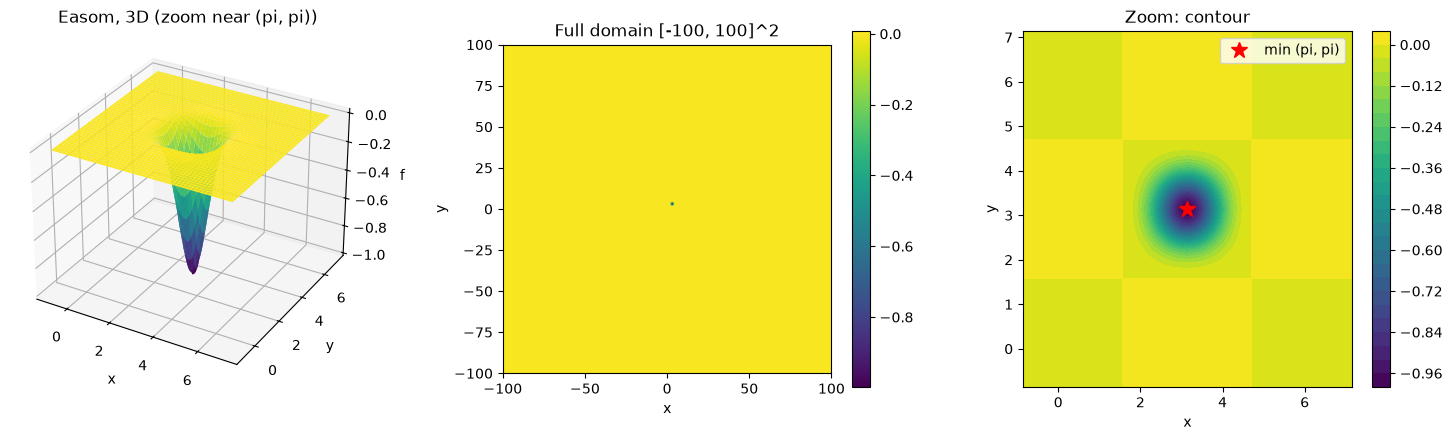

In [3]:
fig = plt.figure(figsize = (15, 4.5))

ax = fig.add_subplot(1, 3, 1, projection = '3d')
g = np.linspace(np.pi - 4, np.pi + 4, 200)
GX, GY = np.meshgrid(g, g)
ax.plot_surface(GX, GY, easom(GX, GY), cmap = 'viridis', linewidth = 0)
ax.set_title('Easom, 3D (zoom near (pi, pi))')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('f')

ax = fig.add_subplot(1, 3, 2)
g = np.linspace(LO, HI, 600)
GX, GY = np.meshgrid(g, g)
im = ax.imshow(easom(GX, GY), extent = [LO, HI, LO, HI], origin = 'lower', cmap = 'viridis')
fig.colorbar(im, ax = ax)
ax.set_title('Full domain [-100, 100]^2')
ax.set_xlabel('x'); ax.set_ylabel('y')

ax = fig.add_subplot(1, 3, 3)
g = np.linspace(np.pi - 4, np.pi + 4, 300)
GX, GY = np.meshgrid(g, g)
cs = ax.contourf(GX, GY, easom(GX, GY), levels = 30, cmap = 'viridis')
fig.colorbar(cs, ax = ax)
ax.plot(*X_OPT, 'r*', markersize = 12, label = 'min (pi, pi)')
ax.set_title('Zoom: contour')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend()

plt.tight_layout()
plt.show()

## 3. Генетичний алгоритм: схема

ГА імітує природний добір: є **популяція** з $N$ особин (кандидатів-розв'язків), і з покоління в покоління кращі особини частіше дають нащадків, а нащадки трохи відрізняються від батьків. Через багато поколінь популяція «стягується» до екстремуму.

**Кодування.** Використаємо дійсне (real-coded) кодування: хромосома особини — вектор $\mathbf{x} = (x, y) \in [-100,100]^2$, гени — це самі координати. (Альтернатива — двійкове кодування, але для неперервних функцій дійсне простіше і точніше.)

**Пристосованість (fitness).** Шукаємо мінімум, тому особина тим краща, чим менше $f(\mathbf{x})$. Порівнюємо особин безпосередньо за $f$.

**Один крок (покоління) $t \to t+1$:**
1. **Елітизм** — $E$ найкращих особин копіюються в нове покоління без змін (найкращий знайдений розв'язок ніколи не втрачається).
2. **Селекція (турнірна)** — для кожного батька випадково обираємо $k$ особин і беремо найкращу з них.
3. **Схрещування (BLX-$\alpha$)** — з імовірністю $p_c$ нащадок від батьків $\mathbf{p}_1, \mathbf{p}_2$ генерується покоординатно:
$$c_j \sim U\big[\min(p_{1j},p_{2j}) - \alpha d_j,\ \max(p_{1j},p_{2j}) + \alpha d_j\big],\qquad d_j = |p_{1j} - p_{2j}|$$
   інакше нащадок — копія $\mathbf{p}_1$.
4. **Мутація (гаусова)** — кожен ген з імовірністю $p_m$ отримує шум: $c_j \leftarrow c_j + \mathcal{N}(0, \sigma_t^2)$. Крок мутації зменшується з часом (спочатку — розвідка всієї області, наприкінці — точне доналаштування):
$$\sigma_t = \sigma_0 \left(\frac{\sigma_{end}}{\sigma_0}\right)^{t/(T-1)}$$
5. **Обмеження області** — координати, що вийшли за $[-100,100]$, обрізаються до меж.

Повторюємо $T$ поколінь, результат — найкраща особина останнього покоління.

Реалізуємо кожен оператор окремою функцією.

In [4]:
def init_population(rng, n):
    return rng.uniform(LO, HI, (n, 2))

def tournament_select(rng, pop, fit, m, k):
    idx = rng.integers(0, len(pop), (m, k))
    winners = idx[np.arange(m), np.argmin(fit[idx], axis = 1)]
    return pop[winners]

def blx_crossover(rng, p1, p2, alpha, pc):
    lo = np.minimum(p1, p2)
    hi = np.maximum(p1, p2)
    d = hi - lo
    kids = rng.uniform(lo - alpha * d, hi + alpha * d)
    no_cx = rng.random(len(p1)) > pc
    kids[no_cx] = p1[no_cx]
    return kids

def gaussian_mutation(rng, kids, pm, sigma):
    mask = rng.random(kids.shape) < pm
    return kids + mask * rng.normal(0, sigma, kids.shape)

rng = np.random.default_rng(1)
p1 = np.array([[0.0, 0.0]]); p2 = np.array([[2.0, 4.0]])
print('BLX children of (0,0) and (2,4):'); print(np.vstack([blx_crossover(rng, p1, p2, 0.5, 1.0) for _ in range(5)]))
print('mutated (1,1) with sigma=0.5, pm=0.5:'); print(np.vstack([gaussian_mutation(rng, np.array([[1.0, 1.0]]), 0.5, 0.5) for _ in range(5)]))

BLX children of (0,0) and (2,4):
[[ 1.0472865   5.60370957]
 [ 2.79459779  0.49465162]
 [ 2.31081038  1.27359309]
 [-0.88976355  4.02810487]
 [ 0.31892687  4.30742963]]
mutated (1,1) with sigma=0.5, pm=0.5:
[[0.85377162 0.60904577]
 [0.86219855 1.        ]
 [1.         1.        ]
 [1.10866097 2.05891938]
 [1.         1.        ]]


Для BLX-0.5 і батьків $(0,0)$, $(2,4)$: $x$-координата нащадка лежить у $[-1, 3]$, $y$ — у $[-2, 6]$. Тобто нащадок може опинитись і **між** батьками (експлуатація), і трохи **за межами** відрізка між ними (розвідка).

## 4. Основний цикл ГА

Параметри:

| параметр | значення | зміст |
|---|---|---|
| $N$ | 100 | розмір популяції |
| $T$ | 150 | кількість поколінь |
| $E$ | 2 | кількість елітних особин |
| $k$ | 3 | розмір турніру |
| $p_c$ | 0.9 | імовірність схрещування |
| $\alpha$ | 0.5 | параметр BLX |
| $p_m$ | 0.3 | імовірність мутації гена |
| $\sigma_0 \to \sigma_{end}$ | 20 $\to$ $10^{-5}$ | крок мутації (10% ширини області $\to$ дуже малий) |

Чому $\sigma_{end} = 10^{-5}$: біля мінімуму $f \approx -1 + 1.5\,r^2$, тому точність по $f$ — це квадрат точності по $x$. При $r \lesssim 10^{-8}$ різниця $1.5\,r^2$ стає меншою за машинне епсилон ($\approx 2\cdot 10^{-16}$), і `float64` уже не розрізняє такі точки. Отже, мутувати з кроком, значно меншим за $10^{-5}$, немає сенсу, а більший крок наприкінці лише додає шум і погіршує точність.

Функція `run_ga` також зберігає історію (популяцію на кожному поколінні, найкраще і середнє значення $f$) — вона потрібна для візуалізації.

In [5]:
def run_ga(N = 100, T = 150, elite = 2, k = 3, pc = 0.9, alpha = 0.5, pm = 0.3,
           sigma0 = 20, sigma_end = 1e-5, seed = None):
    rng = np.random.default_rng(seed)
    pop = init_population(rng, N)
    fit = easom(pop[:, 0], pop[:, 1])
    hist = {'pop': [pop.copy()], 'best': [fit.min()], 'mean': [fit.mean()],
            'best_x': [pop[np.argmin(fit)].copy()], 'sigma': []}

    for t in range(T):
        sigma = sigma0 * (sigma_end / sigma0) ** (t / (T - 1))

        elites = pop[np.argsort(fit)[:elite]]

        m = N - elite
        p1 = tournament_select(rng, pop, fit, m, k)
        p2 = tournament_select(rng, pop, fit, m, k)

        kids = blx_crossover(rng, p1, p2, alpha, pc)
        kids = gaussian_mutation(rng, kids, pm, sigma)
        kids = np.clip(kids, LO, HI)

        pop = np.vstack([elites, kids])
        fit = easom(pop[:, 0], pop[:, 1])

        hist['pop'].append(pop.copy())
        hist['best'].append(fit.min())
        hist['mean'].append(fit.mean())
        hist['best_x'].append(pop[np.argmin(fit)].copy())
        hist['sigma'].append(sigma)

    i = np.argmin(fit)
    return pop[i], fit[i], hist

In [6]:
SEED = 7
x_best, f_best, hist = run_ga(seed = SEED)

print('generation |       x           y       |   best f    |   mean f')
for t in list(range(0, 10)) + list(range(10, 151, 10)):
    bx = hist['best_x'][t]
    print(f'{t:10d} | {bx[0]:11.8f} {bx[1]:11.8f} | {hist["best"][t]:11.3e} | {hist["mean"][t]:10.3e}')

print()
print('found:   x =', x_best, ' f =', f_best)
print('exact:   x =', X_OPT, ' f =', F_OPT)
print('error |x - x*| =', np.linalg.norm(x_best - X_OPT), ',  |f - f*| =', abs(f_best - F_OPT))
print('function evaluations:', 100 * 151)

generation |       x           y       |   best f    |   mean f
         0 | 20.75580506 -4.16070102 | -2.160e-159 |  1.915e-30
         1 |  7.36463200  7.76217446 |  -4.141e-19 | -4.141e-21
         2 |  2.84373942 -3.02895949 |  -2.530e-17 | -3.732e-19
         3 |  2.84373942 -3.02895949 |  -2.530e-17 |  1.356e-05
         4 |  2.84373942 -3.02895949 |  -2.530e-17 |  2.469e-14
         5 | -0.14907653  4.99907094 |  -1.760e-07 | -1.760e-09
         6 | -0.14907653  4.99907094 |  -1.760e-07 | -1.760e-09
         7 |  2.84373942  3.08578081 |  -8.707e-01 | -9.046e-03
         8 |  2.84373942  3.08578081 |  -8.707e-01 | -9.183e-03
         9 |  2.84373942  3.08578081 |  -8.707e-01 | -1.775e-02
        10 |  2.84373942  3.08578081 |  -8.707e-01 | -1.767e-02
        20 |  3.10377296  3.09836975 |  -9.951e-01 | -1.314e-01
        30 |  3.15533989  3.13308442 |  -9.996e-01 | -6.820e-01
        40 |  3.14188617  3.14119805 |  -1.000e+00 | -8.598e-01
        50 |  3.14185179  3.14199523 |  

## 5. Візуалізація роботи алгоритму

### 5.1. Популяція на різних поколіннях

Верхній ряд — уся область $[-100,100]^2$ (видно, як популяція з рівномірно розкиданих точок стягується до $(\pi,\pi)$). Нижній ряд — збільшений фрагмент $[\pi-2,\pi+2]^2$ з лініями рівня $f$ (видно фінальне уточнення). Червона зірка — справжній мінімум, блакитний хрестик — найкраща особина покоління.

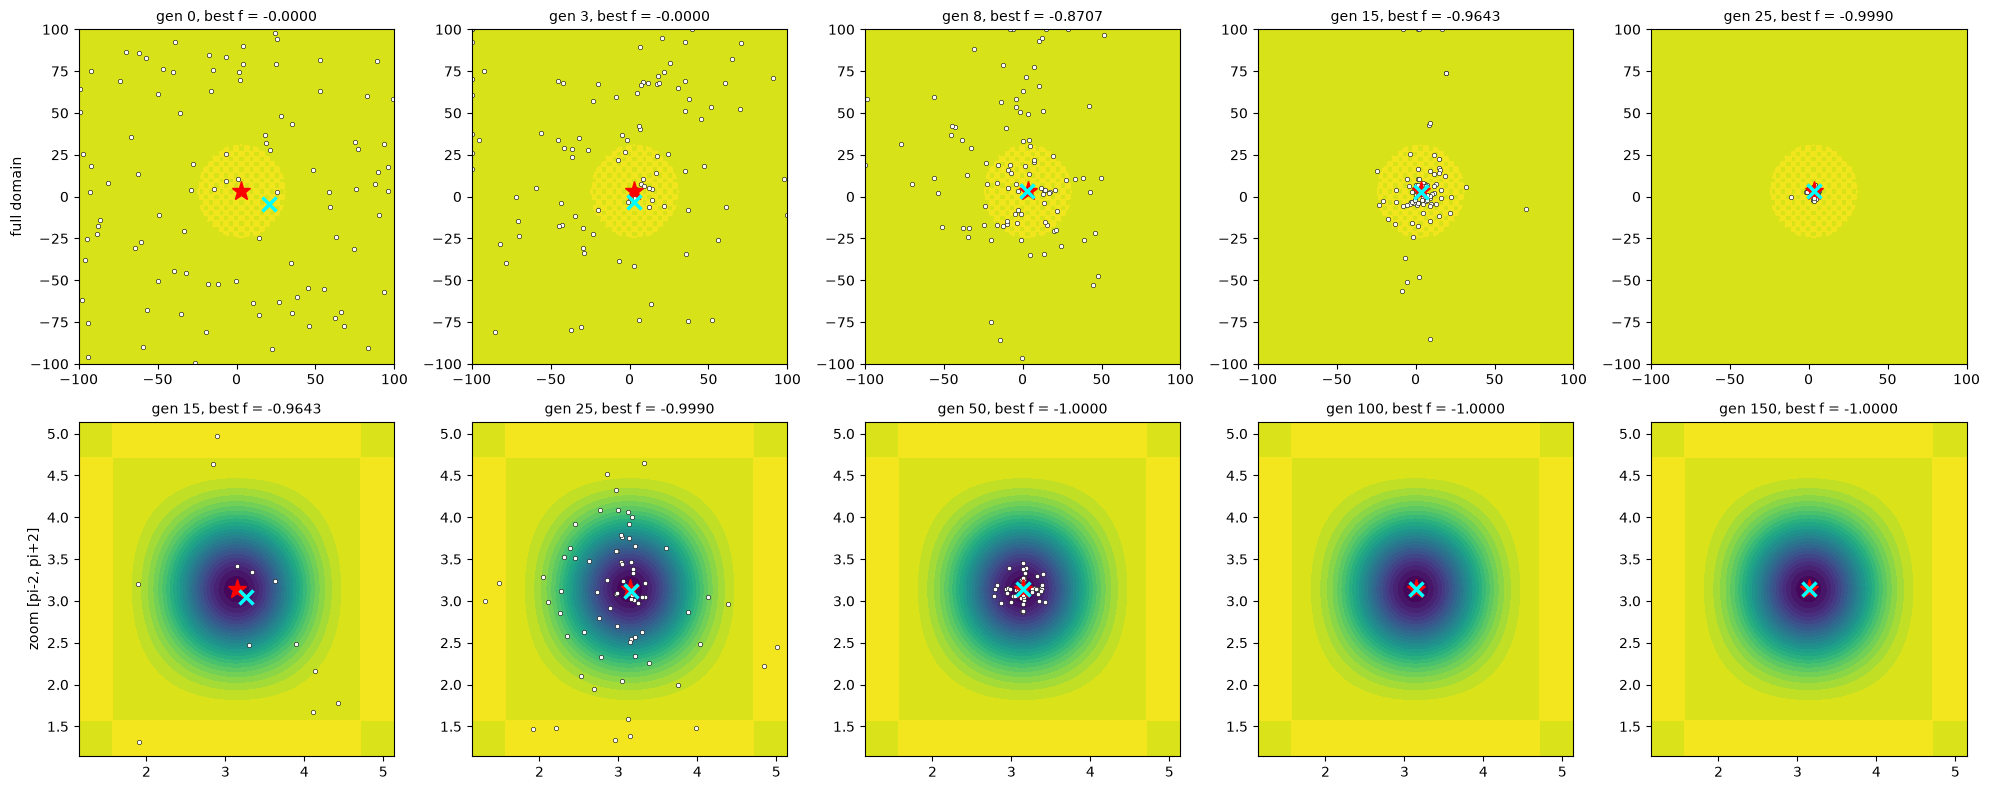

In [7]:
def draw_population(ax, t, half = None):
    if half is None:
        x0, x1, y0, y1 = LO, HI, LO, HI
    else:
        x0, x1, y0, y1 = np.pi - half, np.pi + half, np.pi - half, np.pi + half
    g = np.linspace(x0, x1, 300)
    GX, GY = np.meshgrid(g, np.linspace(y0, y1, 300))
    ax.contourf(GX, GY, easom(GX, GY), levels = 30, cmap = 'viridis')
    P = hist['pop'][t]
    ax.scatter(P[:, 0], P[:, 1], s = 10, c = 'white', edgecolors = 'black', linewidths = 0.4)
    ax.plot(*X_OPT, 'r*', markersize = 14)
    ax.plot(*hist['best_x'][t], 'x', color = 'cyan', markersize = 10, mew = 2.5)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_title(f'gen {t}, best f = {hist["best"][t]:.4f}', fontsize = 10)

gens_full = [0, 3, 8, 15, 25]
gens_zoom = [15, 25, 50, 100, 150]
fig, axes = plt.subplots(2, 5, figsize = (20, 8))
for ax, t in zip(axes[0], gens_full):
    draw_population(ax, t)
for ax, t in zip(axes[1], gens_zoom):
    draw_population(ax, t, half = 2)
axes[0, 0].set_ylabel('full domain'); axes[1, 0].set_ylabel('zoom [pi-2, pi+2]')
plt.tight_layout()
plt.show()

**Що видно на графіках:**
- **Покоління 0** — точки розкидані рівномірно, майже всі мають $f \approx 0$.
- Коло радіуса $\approx 27$ з «шаховою» розміткою — зона, де $e^{-r^2}$ ще не обнулився в `float64`. Там $f$ крихітне, але ненульове, тому селекція стягує популяцію в це коло ще до знаходження «голки».
- Щойно особина потрапляє в «голку» (тут — на 7-му поколінні), вона стає елітною і за ~20 поколінь перетягує туди всю популяцію.
- **Нижній ряд** — уточнення: $\sigma_t$ зменшується, і популяція зливається в одну точку біля $(\pi,\pi)$.

### 5.2. Збіжність

- зліва — найкраще та середнє значення $f$ у популяції за поколіннями;
- посередині — відстань від найкращої особини до справжнього мінімуму $|\mathbf{x}_{best} - (\pi,\pi)|$ (логарифмічна шкала) та розкид популяції (середнє відхилення від центру популяції);
- справа — крок мутації $\sigma_t$.

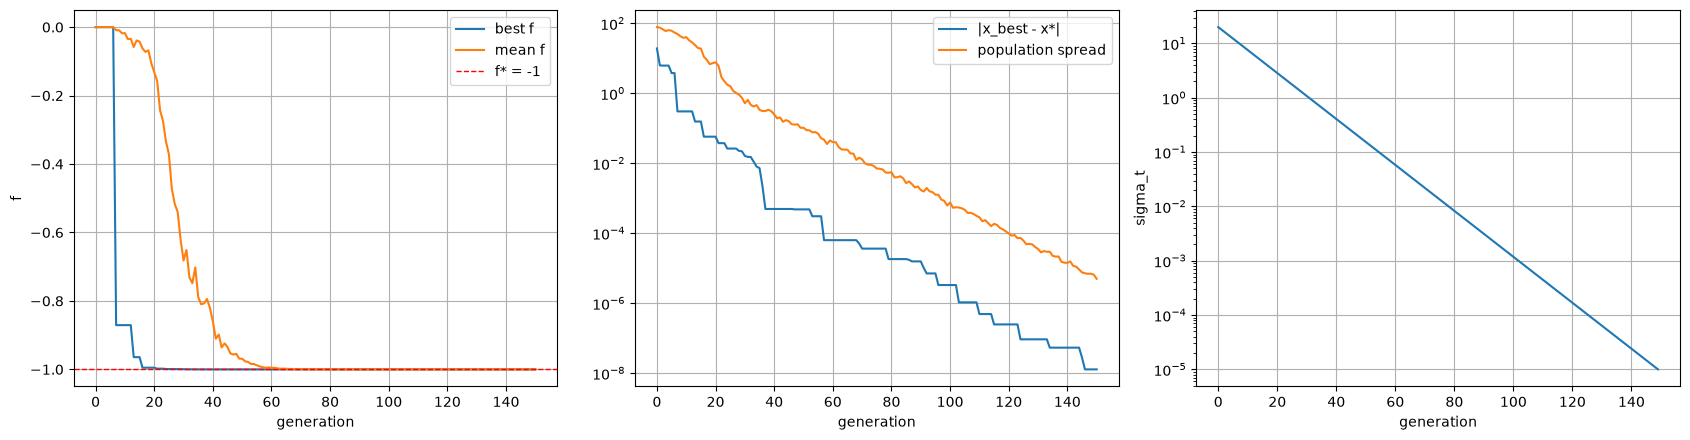

In [8]:
gens = np.arange(len(hist['best']))
dist = [np.linalg.norm(b - X_OPT) for b in hist['best_x']]
spread = [np.mean(np.linalg.norm(P - P.mean(axis = 0), axis = 1)) for P in hist['pop']]

fig, axes = plt.subplots(1, 3, figsize = (17, 4.5))
axes[0].plot(gens, hist['best'], label = 'best f')
axes[0].plot(gens, hist['mean'], label = 'mean f')
axes[0].axhline(F_OPT, color = 'r', ls = '--', lw = 1, label = 'f* = -1')
axes[0].set_xlabel('generation'); axes[0].set_ylabel('f'); axes[0].legend(); axes[0].grid(True)

axes[1].semilogy(gens, dist, label = '|x_best - x*|')
axes[1].semilogy(gens, spread, label = 'population spread')
axes[1].set_xlabel('generation'); axes[1].legend(); axes[1].grid(True)

axes[2].semilogy(gens[:-1], hist['sigma'])
axes[2].set_xlabel('generation'); axes[2].set_ylabel('sigma_t'); axes[2].grid(True)

plt.tight_layout()
plt.show()

### 5.3. Анімація

Покоління за поколінням: зліва — уся область, справа — збільшений фрагмент біля мінімуму.

In [9]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

frames = list(range(0, 30)) + list(range(30, 151, 5))
fig, axes = plt.subplots(1, 2, figsize = (10, 4.6), dpi = 70)

def update(t):
    for ax in axes: ax.clear()
    draw_population(axes[0], t)
    draw_population(axes[1], t, half = 2)
    fig.suptitle(f'Generation {t}')
    return axes

anim = FuncAnimation(fig, update, frames = frames, interval = 200)
plt.close(fig)
HTML(anim.to_jshtml())

## 6. Надійність: багато запусків

ГА стохастичний, тому один вдалий запуск нічого не доводить. Запустимо його 30 разів з різними `seed` і порахуємо частку успішних запусків ($|f - f^*| < 10^{-4}$).

In [10]:
RUNS = 30
res = [run_ga(seed = s) for s in range(RUNS)]
xs = np.array([r[0] for r in res])
fs = np.array([r[1] for r in res])
errs = np.linalg.norm(xs - X_OPT, axis = 1)

print(f'success: {np.mean(np.abs(fs - F_OPT) < 1e-4) * 100:.1f}%')
print(f'best f:  min = {fs.min():.10f}, max = {fs.max():.10f}')
print(f'|x - x*|: median = {np.median(errs):.2e}, max = {errs.max():.2e}')

success: 100.0%
best f:  min = -1.0000000000, max = -1.0000000000
|x - x*|: median = 1.06e-08, max = 4.43e-08
